# Практическая работа № 2
## Комплексные числа. Геометрия комплексных чисел


**Зависимости:** `numpy`, `scipy`, `sympy`, `matplotlib`. Если они не установлены,
выполните в Jupyter `%pip install numpy scipy sympy matplotlib`, затем перезапустите ядро.
Ячейки следует запускать по порядку. В сохранённом ноутбуке результаты уже вычислены.

**Примечания к листку.** В 2.4(e) нижняя граница аргумента больше верхней:
по буквальному условию ответ - пустое множество. Дополнительно показан вариант
с переставленными границами, явно помеченный как предполагаемое исправление.
Два задания с номером 2.10 обозначены ниже как **2.10 (кривые)** и **2.10 (спираль)**.

## Теория

### 1. Алгебраическая форма и основные операции

Комплексное число записывается как $z=x+iy$, где $x,y\in\mathbb R$, $i^2=-1$.
Здесь $x=\operatorname{Re}z$, $y=\operatorname{Im}z$.
Сопряжённое число $\overline z=x-iy$, модуль $|z|=\sqrt{x^2+y^2}$.

$$
(a+ib)(c+id)=(ac-bd)+i(ad+bc),\qquad
\frac{a+ib}{c+id}=\frac{(a+ib)(c-id)}{c^2+d^2},\quad c+id\ne0.
$$

В Python: `z = complex(x, y)` или `z = x + 1j*y`; свойства `z.real`, `z.imag`,
методы `z.conjugate()`, функции `abs(z)`, `np.angle(z)`.
`SymPy` позволяет выполнять точные вычисления с `sp.I`.

### 2. Тригонометрическая и показательная формы

При $z\ne0$:

$$z=r(\cos\varphi+i\sin\varphi)=re^{i\varphi},\qquad r=|z|.$$

Все аргументы отличаются на $2\pi k$. Главное значение будем обозначать
$\operatorname{Arg}z\in(-\pi,\pi]$. Аргумент нуля не определён.
Для выбора квадранта используется `atan2(y, x)`, а не просто $\arctan(y/x)$.
По формуле Муавра:

$$[r(\cos\varphi+i\sin\varphi)]^n=r^n(\cos n\varphi+i\sin n\varphi).$$

### 3. Все комплексные корни

Уравнение $z^n=w\ne0$, где $w=re^{i\theta}$, имеет ровно $n$ различных корней:

$$z_k=r^{1/n}\exp\left(i\frac{\theta+2\pi k}{n}\right),\qquad k=0,\ldots,n-1.$$

На комплексной плоскости это вершины правильного $n$-угольника с центром в нуле.
Операция `w**(1/n)` возвращает только одно значение, поэтому остальные корни
нужно получить отдельно. При $w=0$ единственный корень равен нулю (кратность $n$).

### 4. Геометрические места точек

Число $z=x+iy$ соответствует точке $(x,y)$. Расстояние между $z$ и $z_0$
равно $|z-z_0|$. Уравнение $|z-z_0|=R$ задаёт окружность, а неравенство
$|z-z_0|<R$ - её внутренность. Постоянная сумма расстояний до двух фокусов
задаёт эллипс; равенство расстояний - серединный перпендикуляр.
Линейные неравенства по $x,y$ задают полуплоскости.

Ограничения на аргумент дроби удобнее рассматривать через
$w=(az+b)/(cz+d)=u+iv$. Нужно исключить $cz+d=0$ и $az+b=0$:
в первом случае дробь не определена, во втором не определён её аргумент.
Границы с равенством включаются, строгие границы исключаются.

### 5. Общее уравнение окружности

Если $A,C\in\mathbb R$, $A>0$, $AC<|B|^2$, то

$$A|z|^2+\overline Bz+B\overline z+C=0
\quad\Longleftrightarrow\quad
\left|z+\frac BA\right|^2=\frac{|B|^2-AC}{A^2}.$$

Следовательно, центр $z_0=-B/A$, радиус $R=\sqrt{|B|^2-AC}/A$.
Положение черт над $B$ и $z$ существенно для формулы центра.

### 6. Корни многочлена и определители

По основной теореме алгебры многочлен степени $n$ имеет $n$ комплексных корней
с учётом кратностей. `sp.nroots` находит их с заданной точностью,
`np.roots` выполняет численную проверку. Полезно проверять невязки $p(z_k)$
и формулы Виета, например $\sum z_k=-a_{n-1}/a_n$.
Определитель матрицы с комплексными элементами вычисляется обычными правилами.

### 7. Гамма-функция и обобщённые биномиальные коэффициенты

$$\Gamma(z)=\int_0^\infty t^{z-1}e^{-t}\,dt,\qquad \operatorname{Re}z>0,
\qquad \Gamma(n+1)=n!.$$

За пределами правой полуплоскости используется мероморфное продолжение.
Полюсы $\Gamma$ находятся в $0,-1,-2,\ldots$.

$$C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\Gamma(z-w+1)}.$$

В `scipy.special` доступны `gamma`, `rgamma` ($1/\Gamma$), `loggamma`.
Для изображения фазы удобно вычислять
$L=\log\Gamma(z+1)-\log\Gamma(w+1)-\log\Gamma(z-w+1)$,
а затем $\operatorname{Arg}C_z^w=\operatorname{Arg}e^{i\operatorname{Im}L}$.
Это позволяет не вычислять огромные модули. В нулях и полюсах фаза не определена.
На разрыве главного аргумента нельзя соединять значения $-\pi$ и $\pi$
обычной интерполяцией.

### 8. Множества Жюлиа

Для $f_c(z)=z^2+c$ итерации имеют вид $z_{n+1}=z_n^2+c$.
Заполненное множество $K_c$ состоит из начальных точек с ограниченными орбитами;
множество Жюлиа $J_c=\partial K_c$ является его границей.
Вычисление времени выхода за радиус $R=\max(2,|c|)$ даёт численную картину.
Отсутствие выхода за конечное число итераций ещё не доказывает ограниченность.

Для рациональных функций большой модуль не означает окончательного ухода:
следующая итерация может вернуться в конечную область. Используем обратные
итерации: начинаем с отталкивающей неподвижной точки и последовательно находим
все её прообразы. Их замыкание приближает множество Жюлиа.
Краткое описание и ссылки из задания приведены в решении 2.9.

### 9. Сфера Римана и стереографическая проекция

Расширенная комплексная плоскость $\widehat{\mathbb C}=\mathbb C\cup\{\infty\}$
отождествляется с единичной сферой. Для $z=x+iy$ обратная стереографическая
проекция из северного полюса $N=(0,0,1)$ на плоскость $Z=0$ имеет вид

$$
X=\frac{2x}{1+x^2+y^2},\qquad
Y=\frac{2y}{1+x^2+y^2},\qquad
Z=\frac{x^2+y^2-1}{1+x^2+y^2}.
$$

Проверка: $X^2+Y^2+Z^2=1$. Точка $0$ переходит в южный полюс,
а $\infty$ - в северный. Прямые дополняются точкой $N$ и превращаются
в окружности на сфере; окружности плоскости также переходят в окружности.
Другие кривые изображаются подстановкой их параметрических уравнений.
Для логарифмической спирали:

$$z(\varphi)=ae^{b\varphi}e^{i\varphi},\quad a>0.$$

При $b>0$ её сферический образ приближается к южному полюсу при
$\varphi\to-\infty$ и к северному при $\varphi\to+\infty$.

## Решения задач

### Подключение библиотек и вспомогательные функции

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.special import gamma, rgamma, loggamma
from matplotlib.colors import ListedColormap
from IPython.display import display

sp.init_printing()
np.set_printoptions(precision=10, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def complex_roots(w, n):
    """Все n корней из ненулевого комплексного числа w."""
    w = complex(w)
    if w == 0:
        return np.array([0j])
    k = np.arange(n)
    return abs(w)**(1/n) * np.exp(1j * (np.angle(w) + 2*np.pi*k)/n)

def complex_axes(ax, title, limit=None):
    ax.axhline(0, color='0.5', lw=0.7)
    ax.axvline(0, color='0.5', lw=0.7)
    ax.set(xlabel='Re z', ylabel='Im z', title=title)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.25)
    if limit is not None:
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)

def plot_roots(ax, roots, title):
    radius = max(abs(roots))
    angle = np.linspace(0, 2*np.pi, 500)
    ax.plot(radius*np.cos(angle), radius*np.sin(angle), '--', color='0.7')
    ax.scatter(roots.real, roots.imag, color='#1769aa', s=45, zorder=3)
    for k, z in enumerate(roots):
        ax.annotate(str(k), (z.real, z.imag), xytext=(5, 5),
                    textcoords='offset points')
    complex_axes(ax, title, 1.3*radius)

### 2.1. Алгебраическая, тригонометрическая и показательная формы

**a)**
$$\frac{(5+i)(7-6i)}{3+i}=\frac{41-23i}{3+i}=10-11i.$$
Модуль $r=\sqrt{221}$, главное значение аргумента
$\varphi=-\arctan(11/10)$. Поэтому
$$z=\sqrt{221}(\cos\varphi+i\sin\varphi)=\sqrt{221}e^{i\varphi}.$$

**b)** Так как $1\pm i=\sqrt2e^{\pm i\pi/4}$,
$$\frac{(1+i)^5}{(1-i)^3}=2e^{2\pi i}=2
=2(\cos0+i\sin0)=2e^{i0}.$$

**c)** $-1\pm i\sqrt3=2e^{\pm2\pi i/3}$, поэтому их пятнадцатые
степени равны $2^{15}$. В знаменателях
$(1\pm i)^{20}=2^{10}e^{\pm5\pi i}=-2^{10}$.
Каждая дробь равна $-32$, сумма равна
$$-64=64(\cos\pi+i\sin\pi)=64e^{i\pi}.$$

In [2]:
# 2.1. Точная проверка трёх выражений
expressions = [
    (5+sp.I)*(7-6*sp.I)/(3+sp.I),
    (1+sp.I)**5/(1-sp.I)**3,
    (-1+sp.I*sp.sqrt(3))**15/(1-sp.I)**20
    + (-1-sp.I*sp.sqrt(3))**15/(1+sp.I)**20
]
exact_values = [sp.simplify(sp.expand_complex(z)) for z in expressions]
assert exact_values == [10-11*sp.I, sp.Integer(2), sp.Integer(-64)]
for label, z in zip(['a', 'b', 'c'], exact_values):
    phi = sp.arg(z)
    print(f'{label}) z = {z}; |z| = {sp.simplify(sp.Abs(z))}')
    print(f'   Arg z = {phi} ≈ {float(phi):.10f} рад')

a) z = 10 - 11*I; |z| = sqrt(221)
   Arg z = -atan(11/10) ≈ -0.8329812667 рад
b) z = 2; |z| = 2
   Arg z = 0 ≈ 0.0000000000 рад
c) z = -64; |z| = 64
   Arg z = pi ≈ 3.1415926536 рад


### 2.2. Уравнение $z^8=1+i$

$1+i=\sqrt2e^{i\pi/4}$, поэтому все решения:
$$\boxed{z_k=2^{1/16}e^{i(\pi/32+k\pi/4)},\quad k=0,\ldots,7.}$$
Они лежат на окружности радиуса $2^{1/16}$ и отличаются поворотом на $\pi/4$.

z_0 = 1.0392453187 +0.1023567299i
z_1 = 0.6624802744 +0.8072345500i
z_2 = -0.1023567299 +1.0392453187i
z_3 = -0.8072345500 +0.6624802744i
z_4 = -1.0392453187 -0.1023567299i
z_5 = -0.6624802744 -0.8072345500i
z_6 = 0.1023567299 -1.0392453187i
z_7 = 0.8072345500 -0.6624802744i


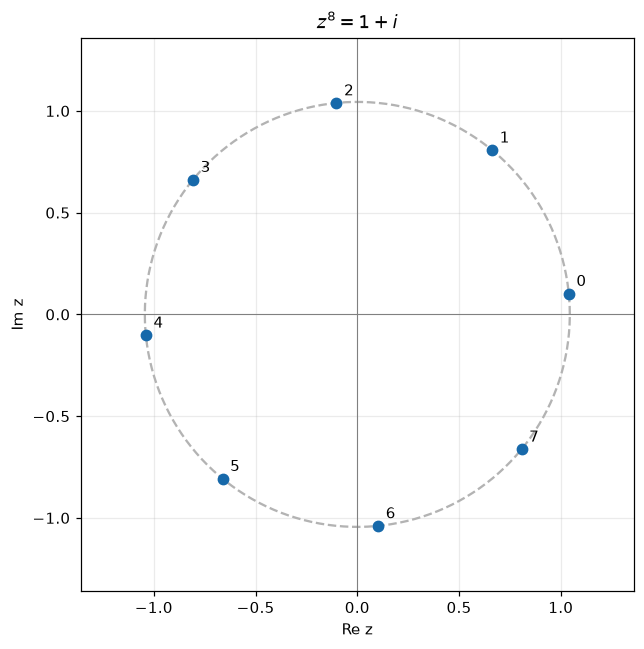

In [3]:
# 2.2. Все восемь корней и их изображение
roots_22 = complex_roots(1+1j, 8)
for k, z in enumerate(roots_22):
    print(f'z_{k} = {z.real:.10f} {z.imag:+.10f}i')
assert np.allclose(roots_22**8, 1+1j, atol=1e-12)
fig, ax = plt.subplots(figsize=(6, 6))
plot_roots(ax, roots_22, r'$z^8=1+i$')
plt.tight_layout()
plt.show()

### 2.3. Вычисление всех корней и изображение на комплексной плоскости

**a)** $\sqrt[8]{1}$:
$$z_k=e^{ik\pi/4},\quad k=0,\ldots,7.$$

**b)**
$$-\frac{18}{1+i\sqrt3}=-\frac92+i\frac{9\sqrt3}{2}=9e^{2\pi i/3},$$
$$z_k=\sqrt3e^{i(\pi/6+k\pi/2)},\quad k=0,\ldots,3.$$

**c)** Корень третьей степени берётся из **всего** выражения под радикалом:
$$\frac{1-5i}{1+i}-5\frac{1+2i}{2-i}+11=(-2-3i)-5i+11=9-8i.$$
Следовательно,
$$z_k=145^{1/6}e^{i(-\arctan(8/9)/3+2\pi k/3)},\quad k=0,1,2.$$

**d)** $1-i=\sqrt2e^{-i\pi/4}$:
$$z_k=2^{1/18}e^{i(-\pi/36+2\pi k/9)},\quad k=0,\ldots,8.$$

a) подкоренное выражение: 1; степень: 8
   z_0 = 1.000000000 +0.000000000i
   z_1 = 0.707106781 +0.707106781i
   z_2 = 0.000000000 +1.000000000i
   z_3 = -0.707106781 +0.707106781i
   z_4 = -1.000000000 +0.000000000i
   z_5 = -0.707106781 -0.707106781i
   z_6 = -0.000000000 -1.000000000i
   z_7 = 0.707106781 -0.707106781i
b) подкоренное выражение: 18*I/(sqrt(3) - I); степень: 4
   z_0 = 1.500000000 +0.866025404i
   z_1 = -0.866025404 +1.500000000i
   z_2 = -1.500000000 -0.866025404i
   z_3 = 0.866025404 -1.500000000i
c) подкоренное выражение: 9 - 8*I; степень: 3
   z_0 = 2.225163491 -0.549759322i
   z_1 = -0.636476206 +2.201927772i
   z_2 = -1.588687284 -1.652168449i
d) подкоренное выражение: 1 - I; степень: 9
   z_0 = 1.035304531 -0.090577410i
   z_1 = 0.851311320 +0.596094603i
   z_2 = 0.268980080 +1.003847327i
   z_3 = -0.439209928 +0.941888729i
   z_4 = -0.941888729 +0.439209928i
   z_5 = -1.003847327 -0.268980080i
   z_6 = -0.596094603 -0.851311320i
   z_7 = 0.090577410 -1.0353045

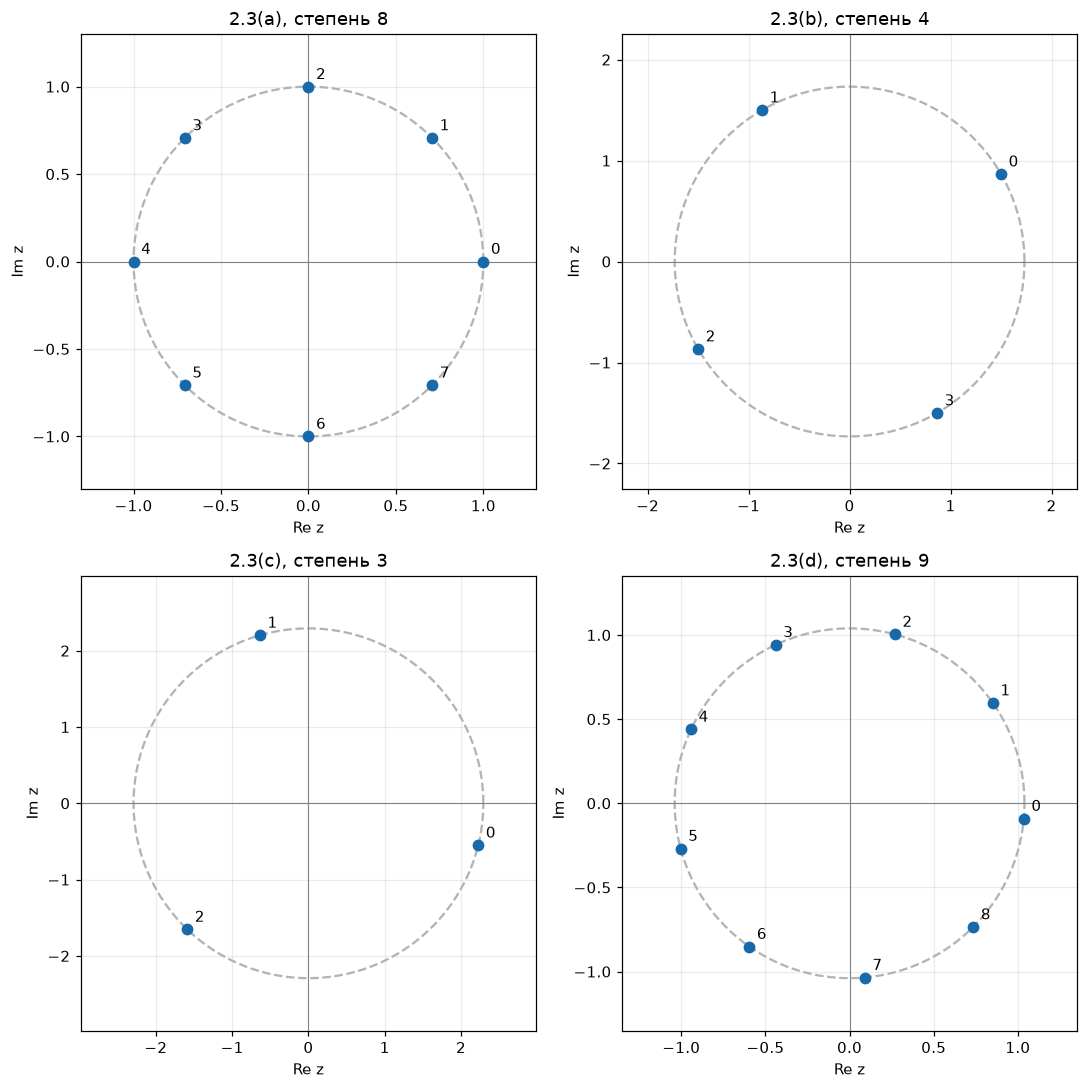

In [4]:
# 2.3. Вычисление радикандов без потери точности
radicands = [sp.Integer(1),
             sp.simplify(-18/(1+sp.I*sp.sqrt(3))),
             sp.simplify((1-5*sp.I)/(1+sp.I)
                         - 5*(1+2*sp.I)/(2-sp.I) + 11),
             1-sp.I]
degrees = [8, 4, 3, 9]
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for label, w, n, ax in zip(['a', 'b', 'c', 'd'], radicands, degrees, axes.flat):
    roots = complex_roots(complex(w), n)
    print(f'{label}) подкоренное выражение: {w}; степень: {n}')
    for k, z in enumerate(roots):
        print(f'   z_{k} = {z.real:.9f} {z.imag:+.9f}i')
    assert np.allclose(roots**n, complex(w), atol=2e-12)
    plot_roots(ax, roots, f'2.3({label}), степень {n}')
plt.tight_layout()
plt.show()

### 2.4. Геометрические места точек

Положим $z=x+iy$; в неравенствах используем главное значение аргумента.

**a)** $|z-i|+|z+i|<4$. Фокусы $(0,\pm1)$, большая полуось $a=2$,
фокусное расстояние $c=1$, малая полуось $b=\sqrt{a^2-c^2}=\sqrt3$.
Ответ - внутренность эллипса:
$$\boxed{\frac{x^2}{3}+\frac{y^2}{4}<1.}$$

**b)** $\operatorname{Re}(z(1-i))=x+y$.
Ответ: полуплоскость $\boxed{x+y<\sqrt2}$, граничная прямая исключается.

**c)** Равенство $|z+i|=|z-i|$ даёт $y=0$; равенство
$|z+1|=|z-i|$ тогда даёт $x=0$. Ответ: $\boxed{z=0}$.

**d)** Для $w=(i-z)/(z+i)$ при $z\ne-i$:
$$\operatorname{Re}w=\frac{1-x^2-y^2}{x^2+(y+1)^2},\qquad
\operatorname{Im}w=\frac{2x}{x^2+(y+1)^2}.$$
Условие $0<\operatorname{Arg}w<\pi/2$ равносильно положительности обеих частей:
$$\boxed{x>0,\quad x^2+y^2<1.}$$
Это правая половина открытого единичного круга; все её границы исключены.

**e)** В листке напечатано
$-2\pi/3\le\operatorname{Arg}((2-iz)/(z+3i))\le-5\pi/6$.
Но $-2\pi/3=-120^\circ>-150^\circ=-5\pi/6$.
Ответ по исходному условию: $\boxed{\varnothing}$.

**f)** Пусть $w=(3-z)/(z+i)$, $z\ne-i$. Обозначим
$$D=x^2+(y+1)^2,\quad U=-x^2-y^2+3x-y,\quad V=x-3y-3.$$
Тогда $\operatorname{Re}w=U/D$, $\operatorname{Im}w=V/D$.
Сектор $-2\pi/3\le\operatorname{Arg}w\le-\pi/3$ задаётся условиями
$\operatorname{Im}w\le-\sqrt3|\operatorname{Re}w|$, $w\ne0$.
Ответ:
$$\boxed{V+\sqrt3U\le0,\quad V-\sqrt3U\le0,\quad z\notin\{-i,3\}.}$$
Граничные дуги включены, их общие концы $-i$ (полюс) и $3$ (нулевой аргумент)
исключены. На рисунках пунктир обозначает исключённую границу,
сплошная линия - включённую, пустой маркер - исключённую точку.

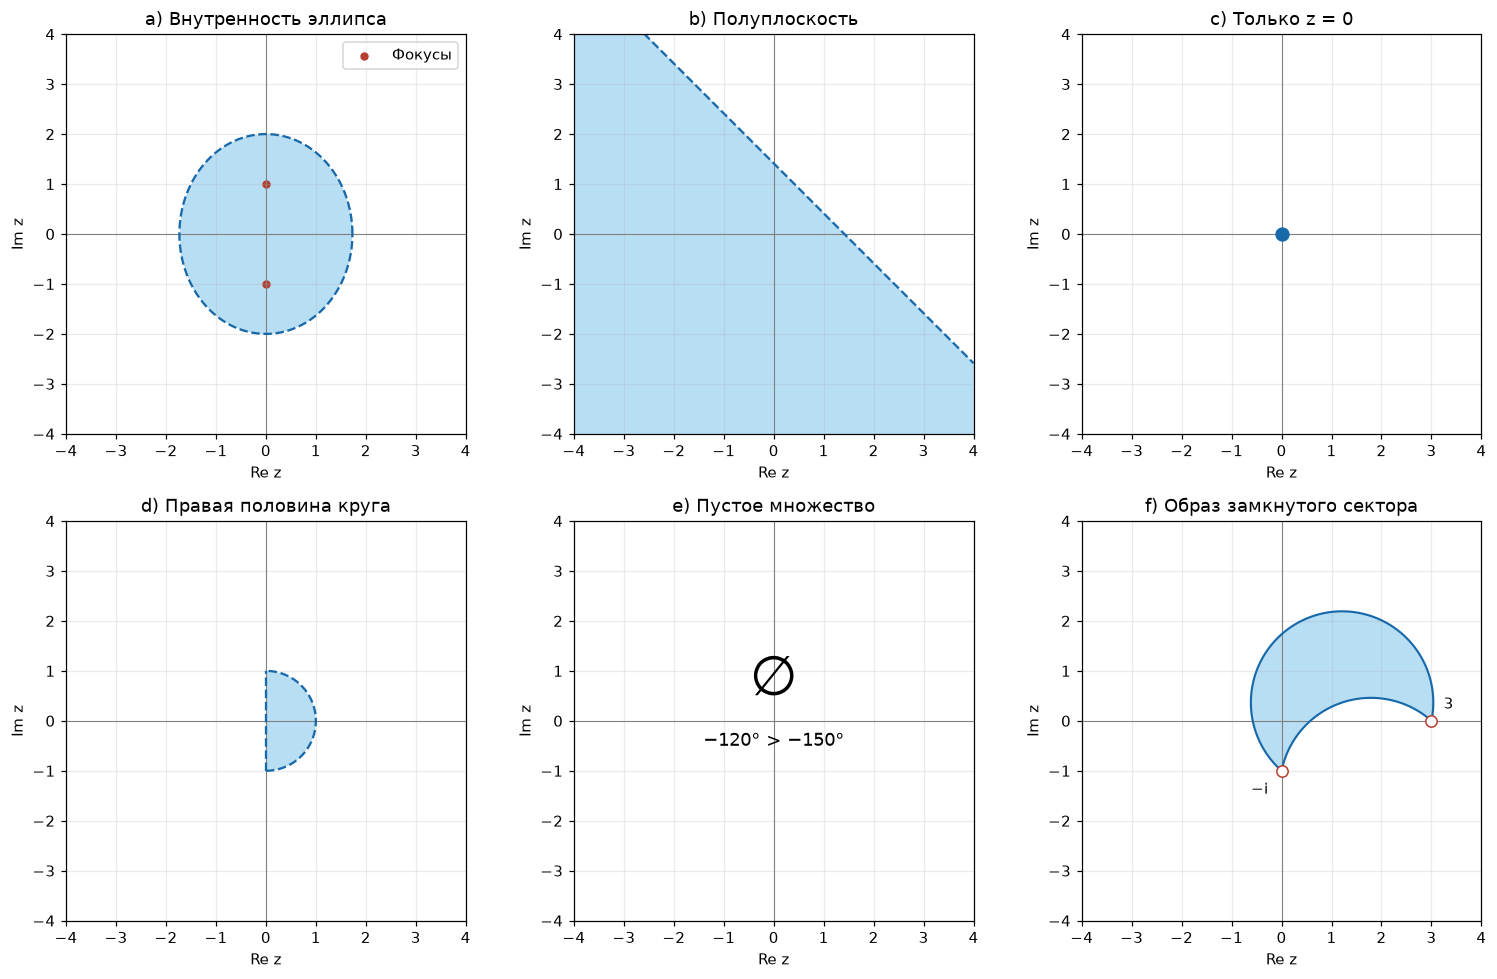

In [5]:
# 2.4. Шесть множеств по напечатанным условиям
grid = np.linspace(-4, 4, 901)
X, Y = np.meshgrid(grid, grid)
U = -X**2 - Y**2 + 3*X - Y
V = X - 3*Y - 3
valid_f = (X**2+(Y+1)**2 > 1e-14) & ((X-3)**2+Y**2 > 1e-14)
masks = [X**2/3+Y**2/4 < 1, X+Y < np.sqrt(2), None,
         (X>0) & (X**2+Y**2 < 1), np.zeros_like(X, dtype=bool),
         (V+np.sqrt(3)*U <= 0) & (V-np.sqrt(3)*U <= 0) & valid_f]
titles = ['a) Внутренность эллипса', 'b) Полуплоскость', 'c) Только z = 0',
          'd) Правая половина круга', 'e) Пустое множество',
          'f) Образ замкнутого сектора']
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
theta = np.linspace(0, 2*np.pi, 600)
for ax, mask, title in zip(axes.flat, masks, titles):
    if mask is not None:
        ax.imshow(mask, extent=(-4, 4, -4, 4), origin='lower',
                  cmap=ListedColormap(['white', '#b8def4']), interpolation='nearest')
    complex_axes(ax, title, 4)
axes[0, 0].plot(np.sqrt(3)*np.cos(theta), 2*np.sin(theta), '--', color='#1769aa')
axes[0, 0].scatter([0, 0], [-1, 1], color='#b63e30', s=20, label='Фокусы')
axes[0, 0].legend(loc='upper right')
axes[0, 1].plot(grid, np.sqrt(2)-grid, '--', color='#1769aa')
axes[0, 2].scatter([0], [0], s=70, color='#1769aa', zorder=4)
t = np.linspace(-np.pi/2, np.pi/2, 400)
axes[1, 0].plot(np.cos(t), np.sin(t), '--', color='#1769aa')
axes[1, 0].plot([0, 0], [-1, 1], '--', color='#1769aa')
axes[1, 1].text(0, 0.5, r'$\varnothing$', fontsize=36, ha='center')
axes[1, 1].text(0, -0.5, '−120° > −150°', ha='center', fontsize=12)
F1 = np.ma.masked_where(V-np.sqrt(3)*U > 0.04, V+np.sqrt(3)*U)
F2 = np.ma.masked_where(V+np.sqrt(3)*U > 0.04, V-np.sqrt(3)*U)
axes[1, 2].contour(X, Y, F1, levels=[0], colors=['#1769aa'], linewidths=1.4)
axes[1, 2].contour(X, Y, F2, levels=[0], colors=['#1769aa'], linewidths=1.4)
axes[1, 2].scatter([0, 3], [-1, 0], facecolors='white', edgecolors='#b63e30',
                   s=55, zorder=5)
axes[1, 2].annotate('−i', (0, -1), xytext=(-20, -15), textcoords='offset points')
axes[1, 2].annotate('3', (3, 0), xytext=(8, 8), textcoords='offset points')
plt.tight_layout()
plt.show()

# Проверка преобразованного условия f на точках вне границ
Z = X + 1j*Y
with np.errstate(divide='ignore', invalid='ignore'):
    W = (3-Z)/(Z+1j)
    arg_w = np.angle(W)
    direct_f = (arg_w >= -2*np.pi/3) & (arg_w <= -np.pi/3) & valid_f
away = valid_f & (abs(V+np.sqrt(3)*U)>1e-7) & (abs(V-np.sqrt(3)*U)>1e-7)
assert np.array_equal(direct_f[away], masks[-1][away])

#### 2.4(e). Дополнительно: предполагаемое исправление границ

Если подразумевался промежуток $-5\pi/6\le\operatorname{Arg}w\le-2\pi/3$,
где $w=(2-iz)/(z+3i)$, то при $z\ne-3i$
$$\operatorname{Re}w=\frac{-x}{x^2+(y+3)^2},\qquad
\operatorname{Im}w=\frac{-x^2-y^2-5y-6}{x^2+(y+3)^2}.$$
Обозначив $T=x^2+y^2+5y+6$, получаем
$$\boxed{x\ge0,\quad x/\sqrt3\le T\le\sqrt3x,\quad z\notin\{-3i,-2i\}.}$$
Это отдельный разбор исправленного условия, не замена ответа $\varnothing$ выше.

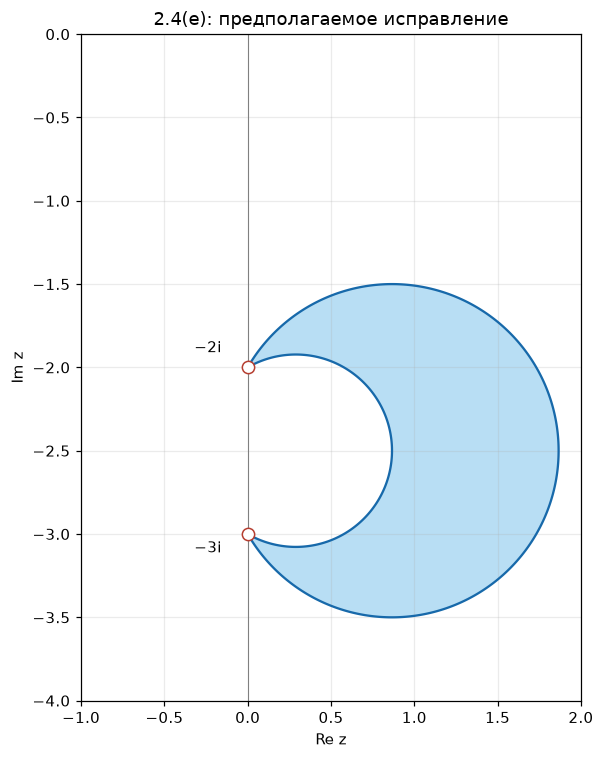

In [6]:
# 2.4(e), только предполагаемый вариант с переставленными границами
gx = np.linspace(-1, 2, 650)
gy = np.linspace(-4, 0, 750)
Xe, Ye = np.meshgrid(gx, gy)
T = Xe**2 + Ye**2 + 5*Ye + 6
valid = (Xe**2+(Ye+3)**2>1e-14) & (Xe**2+(Ye+2)**2>1e-14)
corrected = (Xe>=0) & (T>=Xe/np.sqrt(3)) & (T<=np.sqrt(3)*Xe) & valid
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(corrected, extent=(gx[0],gx[-1],gy[0],gy[-1]), origin='lower',
          cmap=ListedColormap(['white', '#b8def4']), interpolation='nearest')
b1 = np.ma.masked_where(Xe<0, T-Xe/np.sqrt(3))
b2 = np.ma.masked_where(Xe<0, T-np.sqrt(3)*Xe)
ax.contour(Xe, Ye, b1, levels=[0], colors=['#1769aa'])
ax.contour(Xe, Ye, b2, levels=[0], colors=['#1769aa'])
ax.scatter([0,0], [-3,-2], facecolors='white', edgecolors='#b63e30', s=65, zorder=5)
ax.annotate('−3i', (0,-3), xytext=(-35,-12), textcoords='offset points')
ax.annotate('−2i', (0,-2), xytext=(-35,10), textcoords='offset points')
complex_axes(ax, '2.4(e): предполагаемое исправление')
ax.set_xlim(gx[0],gx[-1])
ax.set_ylim(gy[0],gy[-1])
plt.tight_layout()
plt.show()

with np.errstate(divide='ignore', invalid='ignore'):
    We = (2-1j*(Xe+1j*Ye))/(Xe+1j*Ye+3j)
    phase = np.angle(We)
direct = (phase>=-5*np.pi/6) & (phase<=-2*np.pi/3) & valid
away = valid & (abs(T-Xe/np.sqrt(3))>1e-7) & (abs(T-np.sqrt(3)*Xe)>1e-7)
assert np.array_equal(corrected[away], direct[away])

### 2.5*. Доказательство: уравнение окружности

В исходнике записано $A|z|^2+\overline Bz+B\overline z+C=0$.
Делим на $A>0$ и дополняем до квадрата:

$$
|z|^2+\frac{\overline B}{A}z+\frac B A\overline z
+\frac{|B|^2}{A^2}=\frac{|B|^2}{A^2}-\frac C A,
$$
$$\left|z+\frac B A\right|^2=\frac{|B|^2-AC}{A^2}.$$

Правая часть положительна по условию $AC<|B|^2$. Поэтому это невырожденная
окружность с центром и радиусом
$$\boxed{z_0=-\frac B A,\qquad R=\frac{\sqrt{|B|^2-AC}}{A}.}$$
Если $B=b_1+ib_2$, центр имеет координаты $(-b_1/A,-b_2/A)$.

In [7]:
# 2.5. Символьная проверка дополнения до квадрата
A, C, b1, b2, x, y = sp.symbols('A C b1 b2 x y', real=True)
z = x+sp.I*y
B = b1+sp.I*b2
original = A*z*sp.conjugate(z) + sp.conjugate(B)*z + B*sp.conjugate(z) + C
completed = A*((x+b1/A)**2+(y+b2/A)**2) + C-(b1**2+b2**2)/A
assert sp.simplify(original-completed) == 0
print('Разность исходного выражения и дополненного квадрата:', sp.simplify(original-completed))
print('Центр: −B/A; радиус: sqrt(|B|² − A*C)/A, при A > 0.')

Разность исходного выражения и дополненного квадрата: 0
Центр: −B/A; радиус: sqrt(|B|² − A*C)/A, при A > 0.


### 2.6. Все 11 корней многочлена

$$p(t)=t^{11}+t^{10}+t^8-2t^7-t^5+t^4+2t^2+2t+2.$$
Вычислим корни с 30 значащими цифрами и выведем их с 12 знаками после запятой.
Дополнительно проверим невязки при высокой точности и сумму корней по Виету.

**Ответ:**
$$\boxed{\sum_{k=1}^{11}|z_k|\approx11.973384469712},\qquad
\boxed{\max_k\operatorname{Re}z_k\approx1.080601737358}.$$
Максимум действительной части достигается на сопряжённой паре
$1.080601737358\pm0.323893118840i$.

z_ 1 = -1.776769024921 +0.000000000000i
z_ 2 = -0.707434455212 -0.464374725865i
z_ 3 = -0.707434455212 +0.464374725865i
z_ 4 = -0.450037112743 -0.803923144248i
z_ 5 = -0.450037112743 +0.803923144248i
z_ 6 = -0.012500180565 -1.182699081746i
z_ 7 = -0.012500180565 +1.182699081746i
z_ 8 = 0.477754523623 -0.901075230538i
z_ 9 = 0.477754523623 +0.901075230538i
z_10 = 1.080601737358 -0.323893118840i
z_11 = 1.080601737358 +0.323893118840i

Сумма модулей = 11.9733844697121201
Максимальная действительная часть = 1.08060173735784531
Максимальная невязка |p(z_k)| = 5.601e-29


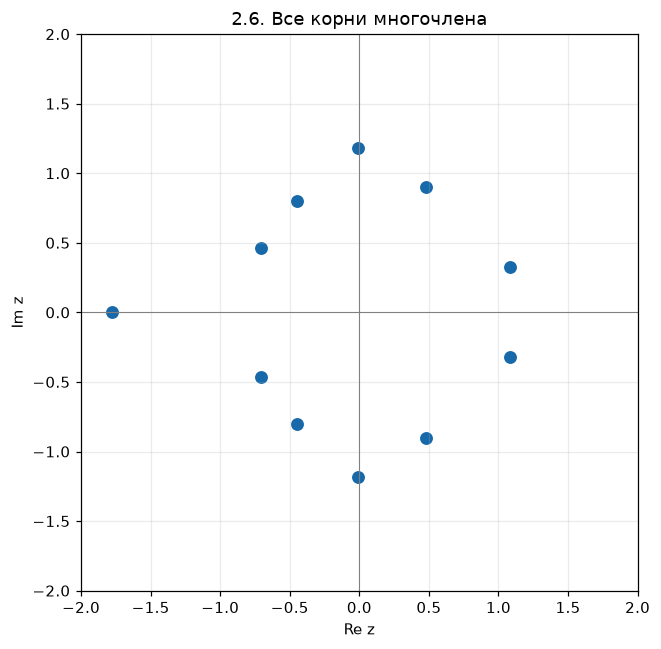

In [8]:
# 2.6. Высокоточные корни, невязки и независимая численная проверка
t = sp.symbols('t')
p = t**11+t**10+t**8-2*t**7-t**5+t**4+2*t**2+2*t+2
roots_high = sp.nroots(p, n=30, maxsteps=200)
roots_numeric = np.array([complex(r) for r in roots_high])
for k, z in enumerate(roots_numeric, 1):
    print(f'z_{k:2d} = {z.real:.12f} {z.imag:+.12f}i')
sum_moduli = sp.N(sum(sp.sqrt(sp.re(z)**2+sp.im(z)**2) for z in roots_high), 18)
max_real = max(sp.re(z) for z in roots_high)
print('\nСумма модулей =', sum_moduli)
print('Максимальная действительная часть =', sp.N(max_real, 18))
residual = max(abs(complex(sp.N(p.subs(t, z), 30))) for z in roots_high)
print('Максимальная невязка |p(z_k)| =', f'{residual:.3e}')
assert residual < 1e-22
assert abs(sum(roots_numeric)+1) < 1e-12
coefficients = [float(a) for a in sp.Poly(p,t).all_coeffs()]
roots_check = np.roots(coefficients)
assert max(min(abs(z-roots_check)) for z in roots_numeric) < 1e-10
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(roots_numeric.real, roots_numeric.imag, color='#1769aa', s=55)
complex_axes(ax, '2.6. Все корни многочлена', 2)
plt.tight_layout()
plt.show()

### 2.7. Обобщённые биномиальные коэффициенты

**a)** При $z=1+i$, $w=1-i$ имеем
$$C_{1+i}^{1-i}=\frac{\Gamma(2+i)}{\Gamma(2-i)\Gamma(1+2i)}
\approx\boxed{4.367449140640+4.851629765158i}.$$

**b)**
$$\boxed{\operatorname{Arg}C_{1+i}^{1-i}\approx0.837869369550\text{ рад}
\approx48.006378658505^\circ}.$$

**c)** В PDF верхний индекс равен **$1/z$**, то есть требуется
$$\operatorname{Arg}C_z^{1/z}=\mathrm{const},\quad z=x+iy.$$
Поэтому строим фазу
$$L(z)=\log\Gamma(z+1)-\log\Gamma(1+1/z)-\log\Gamma(z-1/z+1).$$
Точка $z=0$, нули и полюсы исключаются. Для уровня $\theta$ рисуем
$\operatorname{Im}(e^{-i\theta}e^{i\operatorname{Im}L})=0$ только там, где
действительная часть положительна. Так линии не соединяются через разрыв
главного аргумента на отрицательном действительном луче.

C = 4.367449140640 +4.851629765158i
Arg C = 0.837869369550 рад = 48.006378658505°


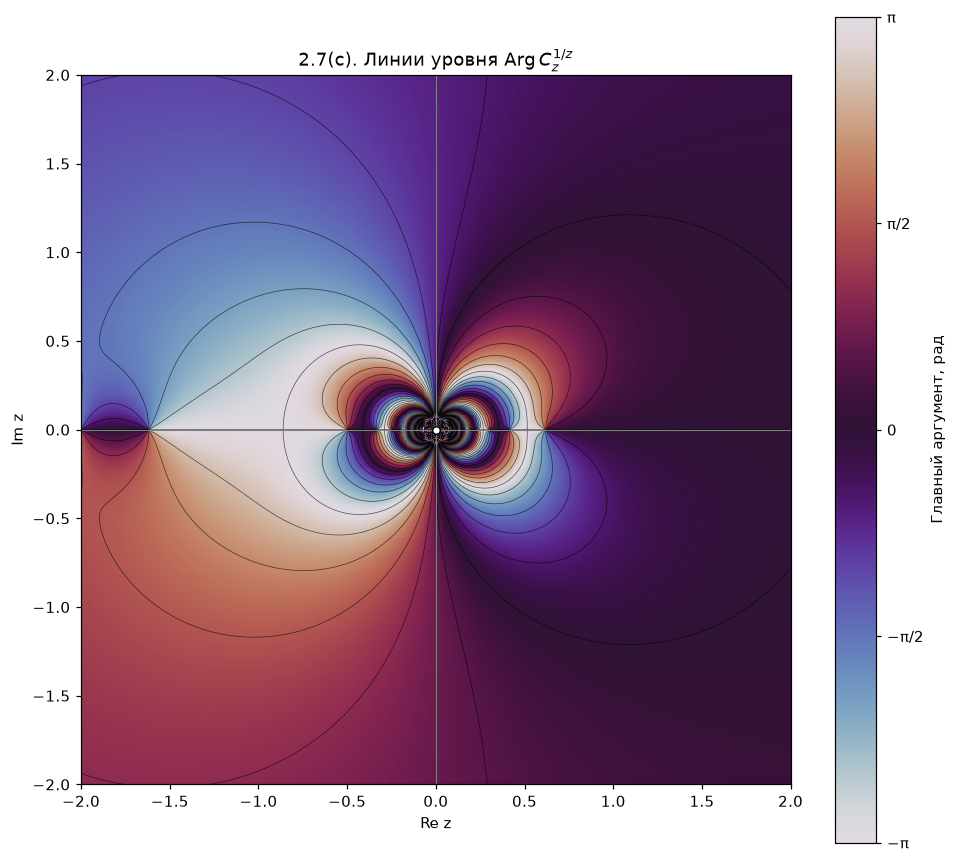

In [9]:
# 2.7(a,b). gamma и rgamma для комплексных аргументов
coefficient = gamma(2+1j)*rgamma(2-1j)*rgamma(1+2j)
argument = np.angle(coefficient)
print(f'C = {coefficient.real:.12f} {coefficient.imag:+.12f}i')
print(f'Arg C = {argument:.12f} рад = {np.degrees(argument):.12f}°')
assert np.isclose(coefficient, 4.367449140640149+4.851629765157829j)

# 2.7(c). Сетка с чётным числом узлов не содержит z=0 и действительную ось
axis = np.linspace(-2,2,750)
X7, Y7 = np.meshgrid(axis,axis)
Z7 = X7+1j*Y7
with np.errstate(divide='ignore',invalid='ignore',over='ignore'):
    L = loggamma(Z7+1)-loggamma(1+1/Z7)-loggamma(Z7-1/Z7+1)
phasor = np.exp(1j*L.imag)
valid7 = np.isfinite(L) & (abs(Z7)>0.018)
phase7 = np.ma.masked_where(~valid7,np.angle(phasor))
fig, ax = plt.subplots(figsize=(9,8))
im = ax.imshow(phase7, origin='lower', extent=(-2,2,-2,2),
               cmap='twilight', vmin=-np.pi, vmax=np.pi, interpolation='nearest')
levels = np.linspace(-np.pi,np.pi,13)[:-1]
for theta in levels:
    rotated = phasor*np.exp(-1j*theta)
    field = np.ma.masked_where(~valid7 | (rotated.real<=0), rotated.imag)
    ax.contour(X7,Y7,field,levels=[0],colors=['black'],linewidths=0.45,alpha=0.65)
ax.scatter([0],[0], facecolors='white',edgecolors='black',s=25,zorder=4)
complex_axes(ax, r'2.7(c). Линии уровня $\operatorname{Arg} C_z^{1/z}$', 2)
ax.grid(False)
bar = fig.colorbar(im,ax=ax,ticks=[-np.pi,-np.pi/2,0,np.pi/2,np.pi])
bar.ax.set_yticklabels(['−π','−π/2','0','π/2','π'])
bar.set_label('Главный аргумент, рад')
plt.tight_layout()
plt.show()

### 2.8. Определитель $A+\lambda I$

Корни четырнадцатой степени из единицы имеют вид
$e^{2\pi ik/14}$. Положительная мнимая часть соответствует $k=1,\ldots,6$.
Наибольшая действительная часть среди них достигается при $k=1$, поэтому
$$\lambda=e^{i\pi/7}.$$
Для $A=\begin{pmatrix}7&5\\6&2\end{pmatrix}$:
$$\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16.$$
Следовательно,
$$\boxed{\operatorname{Re}\det=\cos(2\pi/7)+9\cos(\pi/7)-16
\approx-7.267790387019494},$$
$$\boxed{\operatorname{Im}\det=\sin(2\pi/7)+9\sin(\pi/7)
\approx4.686785134526053}.$$

In [10]:
# 2.8. Выбор λ и проверка определителя
roots14 = complex_roots(1,14)
upper = roots14[roots14.imag>1e-12]
lam = upper[np.argmax(upper.real)]
A8 = np.array([[7,5],[6,2]],dtype=complex)
det8 = np.linalg.det(A8+lam*np.eye(2))
assert np.allclose(lam,np.exp(1j*np.pi/7))
assert np.allclose(det8,lam**2+9*lam-16)
print('λ =',lam)
print(f'Re det(A + λI) = {det8.real:.15f}')
print(f'Im det(A + λI) = {det8.imag:.15f}')

λ = (0.9009688679024191+0.4338837391175581j)
Re det(A + λI) = -7.267790387019490
Im det(A + λI) = 4.686785134526054


### 2.9*. Небольшое исследование множеств Жюлиа

**a, b) Материалы из листка:** [Множество Жюлиа, Wikipedia](https://ru.wikipedia.org/wiki/Множество_Жюлиа)
и [Julia sets: реализация на Python](https://blbadger.github.io/julia-sets#julia-sets-are-fractals).

Множество Жюлиа описывает неустойчивую динамику в окрестности начальной точки.
Для многочлена оно является границей заполненного множества ограниченных орбит.
Метод времени выхода удобен для полиномов; метод обратных итераций позволяет
строить множества для рациональных функций. Изображение всегда имеет конечное
разрешение и конечную глубину итераций. Это численное приближение.

**в)** Строим изображения для $c=-0.1+0.65i$ и $c=0.28+0.009i$.
Время первого выхода обозначено цветом; точки без выхода за 1000 шагов
показаны чёрным. Большое время выхода выделяет окрестность множества Жюлиа.
Размер изображения и число итераций можно изменять в параметрах функции.

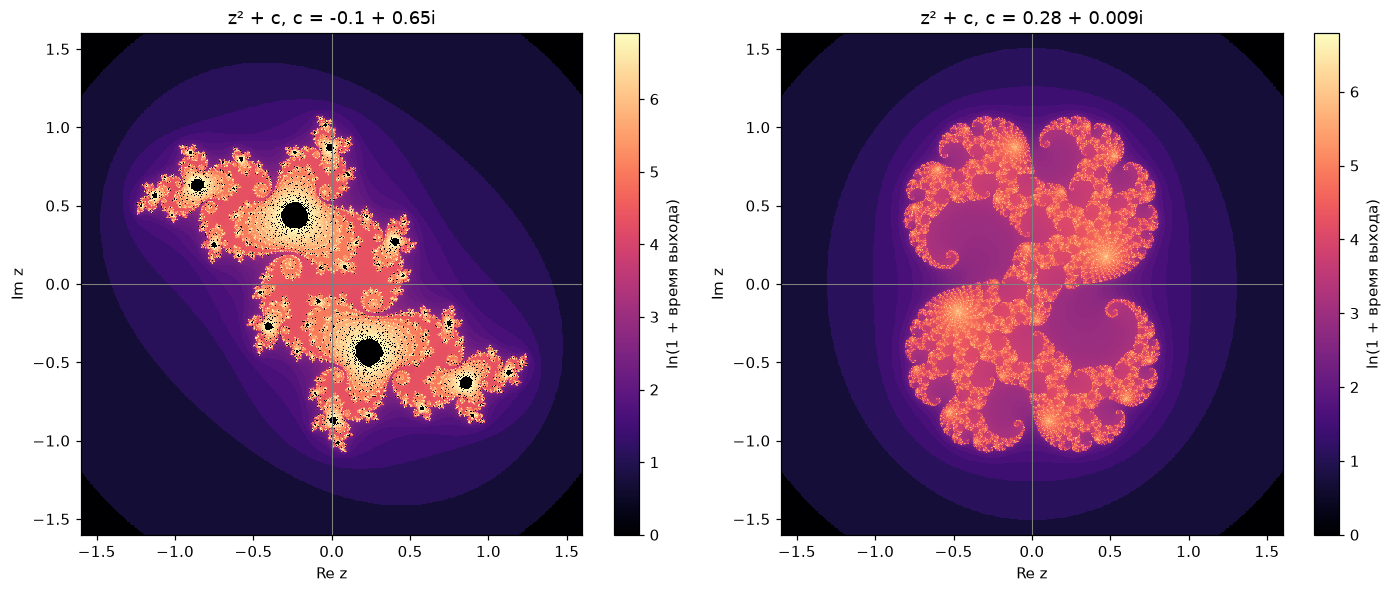

In [11]:
# 2.9(в). Векторизованное вычисление времени выхода
def julia_escape(c, size=650, max_iter=1000, limit=1.6):
    coordinates = np.linspace(-limit,limit,size)
    z = coordinates[None,:]+1j*coordinates[:,None]
    radius = max(2.0,abs(c))
    active = abs(z)<=radius
    times = np.full(z.shape,max_iter,dtype=np.int32)
    times[~active] = 0
    for n in range(1,max_iter+1):
        if not active.any():
            break
        z[active] = z[active]**2+c
        escaped = active & (abs(z)>radius)
        times[escaped] = n
        active[escaped] = False
    return times

fig, axes = plt.subplots(1,2,figsize=(13,6))
cmap = plt.colormaps['magma'].copy()
cmap.set_bad('black')
for ax,c in zip(axes,[-0.1+0.65j,0.28+0.009j]):
    times = julia_escape(c)
    picture = np.ma.masked_where(times==1000,np.log1p(times))
    im = ax.imshow(picture,origin='lower',extent=(-1.6,1.6,-1.6,1.6),
                   cmap=cmap,interpolation='nearest')
    complex_axes(ax,f'z² + c, c = {c.real:g} + {c.imag:g}i',1.6)
    ax.grid(False)
    fig.colorbar(im,ax=ax,shrink=0.8,label='ln(1 + время выхода)')
plt.tight_layout()
plt.show()

**г)** Рассматриваем
$$f_1(z)=\frac{iz^5-1}{z^5-i},\qquad f_2(z)=\frac{z^2+i}{1-z^2}.$$
Показанный в PDF критерий остановки при большом $|z|$ нельзя напрямую
перенести на рациональные функции: например, $f_1(\infty)=i$,
$f_2(\infty)=-1$. Поэтому используем все обратные ветви:

$$f_1(z)=w\ \Longrightarrow\ z^5=\frac{iw-1}{w-i},$$
$$f_2(z)=w\ \Longrightarrow\ z^2=\frac{w-i}{w+1}.$$

Начальную точку выбираем среди неподвижных точек с $|f'_j(z)|>1$.
Они принадлежат множеству Жюлиа. Неподвижные точки находятся из уравнений
$z^6-iz^5-iz+1=0$ и $z^3+z^2-z+i=0$ соответственно.
Далее сохраняем все $5^8$ и $2^{19}$ прообразы на конечном уровне.
Это изображения самих множеств Жюлиа точками, без раскраски бассейнов притяжения.

f1: начальная точка (0.937596213679814+0.6386278671974613j); |f′|=4.18055163; точек 390625
f2: начальная точка (0.8477788024419386-0.36816117902430134j); |f′|=4.64002608; точек 524288


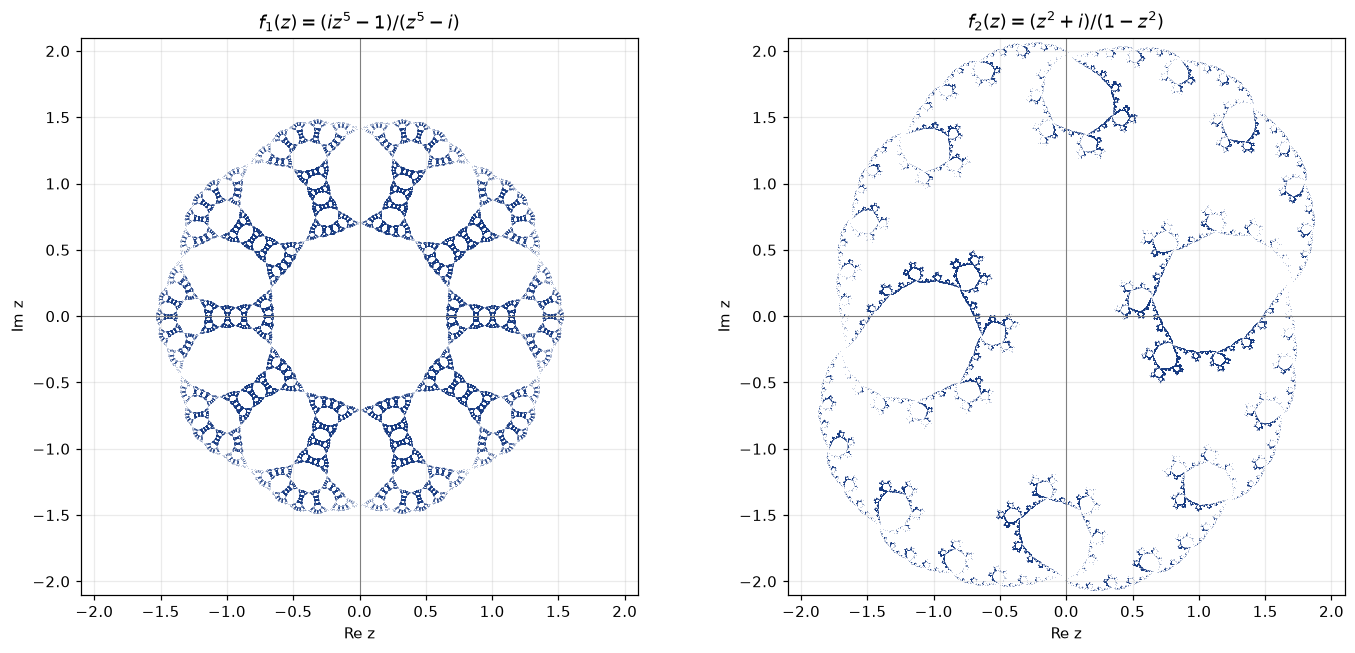

In [12]:
# 2.9(г). Все обратные ветви рациональных функций
def rational_preimages(w,which):
    w = np.asarray(w,dtype=complex)
    if which==1:
        q,n = (1j*w-1)/(w-1j),5
    else:
        q,n = (w-1j)/(w+1),2
    angles = (np.angle(q)[:,None]+2*np.pi*np.arange(n)[None,:])/n
    return (abs(q)[:,None]**(1/n)*np.exp(1j*angles)).ravel()

def rational_map(z,which):
    return (1j*z**5-1)/(z**5-1j) if which==1 else (z**2+1j)/(1-z**2)

def repelling_fixed_point(which):
    if which==1:
        candidates = np.roots([1,-1j,0,0,0,-1j,1])
        derivatives = 10*candidates**4/(candidates**5-1j)**2
    else:
        candidates = np.roots([1,1,-1,1j])
        derivatives = 2*candidates*(1+1j)/(1-candidates**2)**2
    index = np.argmax(abs(derivatives))
    seed = candidates[index]
    assert abs(derivatives[index])>1
    assert abs(rational_map(seed,which)-seed)<1e-10
    return seed,abs(derivatives[index])

fig,axes = plt.subplots(1,2,figsize=(13,6))
for which,depth,ax in zip([1,2],[8,19],axes):
    seed,multiplier = repelling_fixed_point(which)
    points = np.array([seed])
    for _ in range(depth):
        points = rational_preimages(points,which)
    assert np.isfinite(points).all()
    # Проверяем уравнение f(z)=w для всех ветвей на нескольких точках
    parents = np.array([seed,0.4+0.7j,-0.2+0.3j])
    children = rational_preimages(parents,which)
    degree = 5 if which==1 else 2
    assert np.allclose(rational_map(children,which),np.repeat(parents,degree),atol=1e-10)
    print(f'f{which}: начальная точка {seed}; |f′|={multiplier:.8f}; точек {len(points)}')
    ax.scatter(points.real,points.imag,s=0.06,color='#173b82',rasterized=True,linewidths=0)
    title = r'$f_1(z)=(iz^5-1)/(z^5-i)$' if which==1 else r'$f_2(z)=(z^2+i)/(1-z^2)$'
    complex_axes(ax,title,2.1)
plt.tight_layout()
plt.show()

### 2.10*. Кривые на сфере Римана

В условии не заданы конкретные коэффициенты кривых. Возьмём представителей:

| Кривая | Параметризация на комплексной плоскости |
|---|---|
| Прямая $y=1/2$ | $z(t)=t+i/2$ |
| Окружность $x^2+y^2=1$ | $z(t)=e^{it}$, $0\le t\le2\pi$ |
| Парабола $y=x^2$ | $z(t)=t+it^2$ |
| Гипербола $x^2-y^2=1$ | $z_\pm(t)=\pm\cosh t+i\sinh t$ |

Подставим их в формулы стереографической проекции. Окружность $|z|=1$
переходит в экватор $Z=0$. Неограниченные ветви прямой, параболы и гиперболы
стремятся к северному полюсу, который соответствует $\infty$.
На графиках красным показаны сферические образы, синим - исходные кривые
в плоскости $Z=0$. Отрезки исходных кривых ограничены окном рисунка.

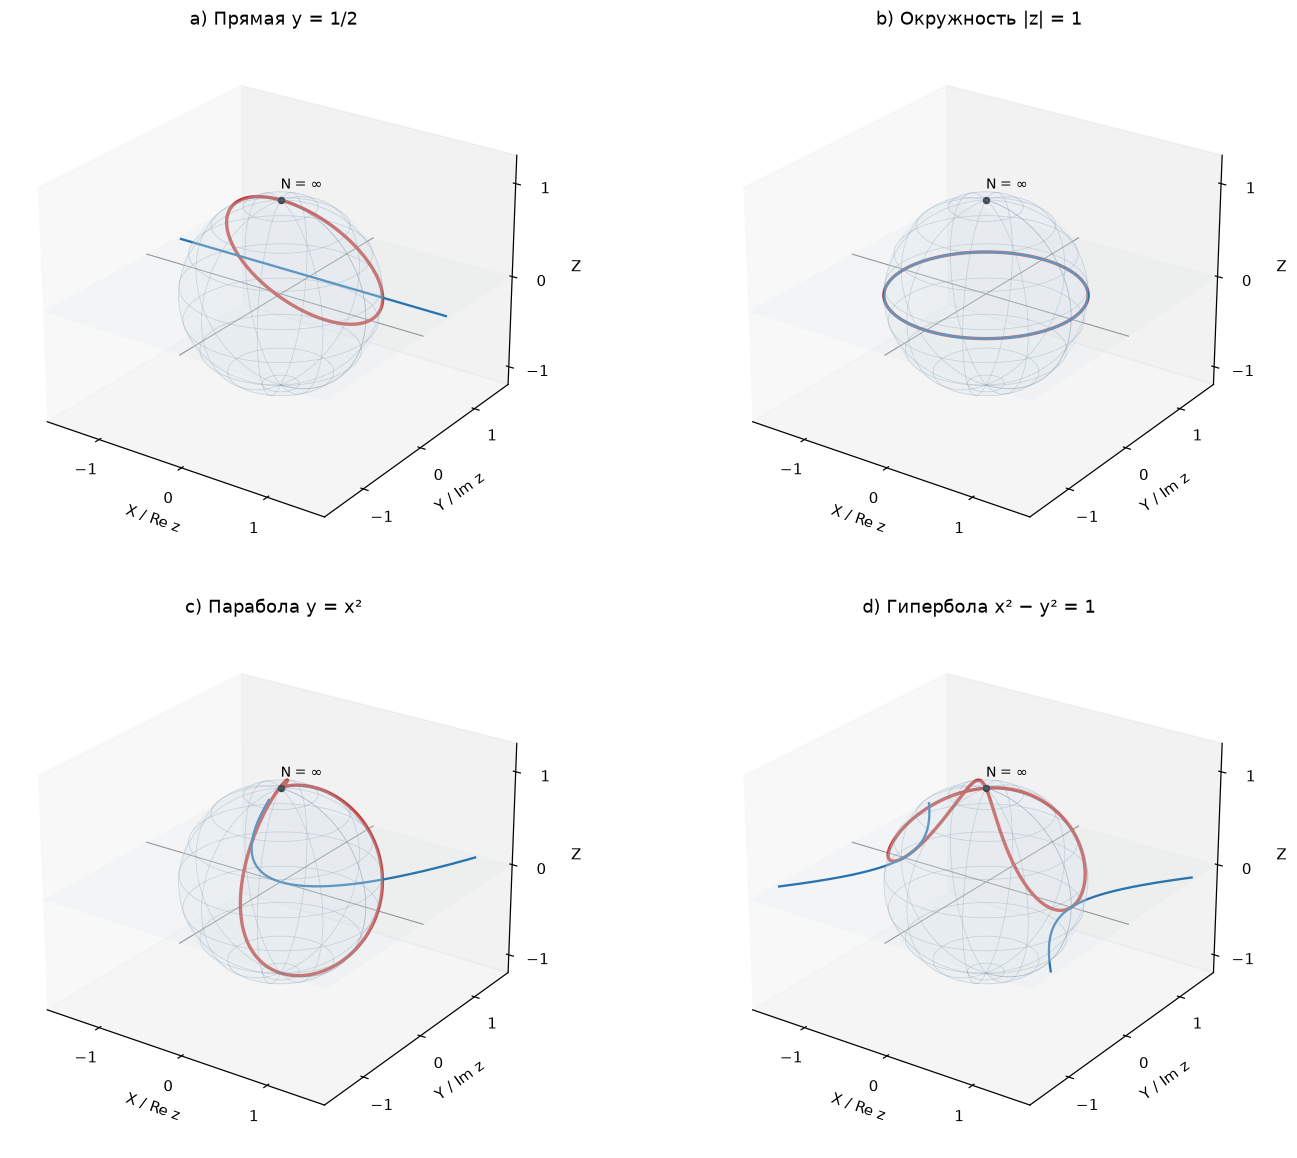

In [13]:
# 2.10 (кривые). Стереографическая проекция на единичную сферу
def stereographic(z):
    z = np.asarray(z,dtype=complex)
    r2 = abs(z)**2
    return 2*z.real/(1+r2),2*z.imag/(1+r2),(r2-1)/(1+r2)

def sphere_axes(ax,title):
    longitude = np.linspace(0,2*np.pi,70)
    latitude = np.linspace(0,np.pi,35)
    xx = np.outer(np.cos(longitude),np.sin(latitude))
    yy = np.outer(np.sin(longitude),np.sin(latitude))
    zz = np.outer(np.ones_like(longitude),np.cos(latitude))
    ax.plot_surface(xx,yy,zz,color='#dde9f2',alpha=0.17,linewidth=0,shade=False)
    ax.plot_wireframe(xx,yy,zz,rstride=7,cstride=4,color='#66849c',alpha=0.28,linewidth=0.5)
    plane = np.array([-1.65,1.65])
    px,py = np.meshgrid(plane,plane)
    ax.plot_surface(px,py,np.zeros_like(px),color='#c8d5dc',alpha=0.10,shade=False)
    ax.plot([-1.65,1.65],[0,0],[0,0],color='0.55',lw=0.7)
    ax.plot([0,0],[-1.65,1.65],[0,0],color='0.55',lw=0.7)
    ax.scatter([0],[0],[1],color='black',s=15)
    ax.text(0,0,1.12,'N = ∞',fontsize=9)
    ax.set(xlim=(-1.65,1.65),ylim=(-1.65,1.65),zlim=(-1.2,1.3),
           xlabel='X / Re z',ylabel='Y / Im z',zlabel='Z',title=title)
    ax.set_box_aspect((3.3,3.3,2.5))
    ax.view_init(elev=25,azim=-55)
    ax.grid(False)
    ax.set_xticks([-1,0,1])
    ax.set_yticks([-1,0,1])
    ax.set_zticks([-1,0,1])

t = np.sinh(np.linspace(-9,9,3000))
theta = np.linspace(0,2*np.pi,1200)
h = np.linspace(-10,10,3000)
curves = [[t+0.5j],[np.exp(1j*theta)],[t+1j*t**2],
          [np.cosh(h)+1j*np.sinh(h),-np.cosh(h)+1j*np.sinh(h)]]
titles = ['a) Прямая y = 1/2','b) Окружность |z| = 1',
          'c) Парабола y = x²','d) Гипербола x² − y² = 1']
fig = plt.figure(figsize=(13,11))
for index,(branches,title) in enumerate(zip(curves,titles),1):
    ax = fig.add_subplot(2,2,index,projection='3d')
    sphere_axes(ax,title)
    for branch in branches:
        sx,sy,sz = stereographic(branch)
        assert np.allclose(sx*sx+sy*sy+sz*sz,1,atol=1e-12)
        ax.plot(sx,sy,sz,color='#c43732',lw=2.2)
        visible = (abs(branch.real)<=1.6)&(abs(branch.imag)<=1.6)
        flat = np.where(visible,branch,np.nan+1j*np.nan)
        ax.plot(flat.real,flat.imag,np.zeros(len(flat)),color='#1769aa',lw=1.5)
fig.subplots_adjust(left=0.02,right=0.97,bottom=0.03,top=0.95,wspace=0.08,hspace=0.12)
plt.show()

### 2.10*. Логарифмическая спираль на сфере Римана

Пусть $r=ae^{b\varphi}$. Выберем $a=1$, $b=0.18$ (в листке численные
значения параметров не заданы). Тогда
$$x=ae^{b\varphi}\cos\varphi,\qquad y=ae^{b\varphi}\sin\varphi.$$
Сферический образ:
$$X=\frac{2ae^{b\varphi}\cos\varphi}{1+a^2e^{2b\varphi}},\qquad
Y=\frac{2ae^{b\varphi}\sin\varphi}{1+a^2e^{2b\varphi}},\qquad
Z=\frac{a^2e^{2b\varphi}-1}{1+a^2e^{2b\varphi}}.$$

Вместо больших экспонент можно использовать $s=\ln a+b\varphi$:
$$\boxed{X=\frac{\cos\varphi}{\cosh s},\quad
Y=\frac{\sin\varphi}{\cosh s},\quad Z=\tanh s.}$$
При $b>0$ спираль соединяет в пределе южный и северный полюсы.
При $b<0$ направления меняются; при $b=0$ получается окружность.
На левом рисунке показана часть плоской спирали, на правом - её образ
для более широкого диапазона параметра.

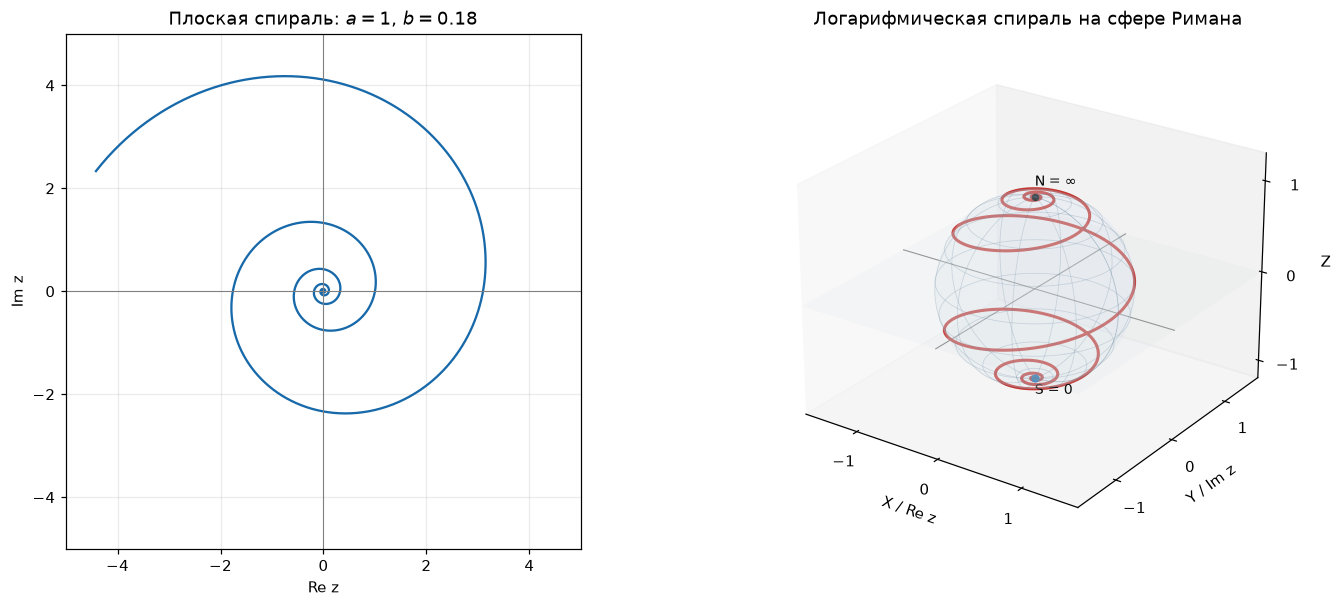

Параметры: a=1.0, b=0.18; φ от -37.699 до 37.699.
Z в начале ≈ -0.999997448, Z в конце ≈ 0.999997448.


In [14]:
# 2.10 (спираль). Параметры можно менять
a,b = 1.0,0.18
phi = np.linspace(-12*np.pi,12*np.pi,6500)
s = np.log(a)+b*phi
sx,sy,sz = np.cos(phi)/np.cosh(s),np.sin(phi)/np.cosh(s),np.tanh(s)
z_spiral = np.exp(s+1j*phi)
assert np.allclose(sx*sx+sy*sy+sz*sz,1,atol=1e-12)
assert np.allclose(np.array(stereographic(z_spiral)),np.array([sx,sy,sz]),atol=1e-12)

fig = plt.figure(figsize=(13,6))
ax1 = fig.add_subplot(1,2,1)
visible = abs(z_spiral)<=5
ax1.plot(np.where(visible,z_spiral.real,np.nan),
         np.where(visible,z_spiral.imag,np.nan),color='#1769aa',lw=1.5)
complex_axes(ax1,fr'Плоская спираль: $a={a:g}$, $b={b:g}$',5)
ax2 = fig.add_subplot(1,2,2,projection='3d')
sphere_axes(ax2,'Логарифмическая спираль на сфере Римана')
ax2.plot(sx,sy,sz,color='#c43732',lw=2)
ax2.scatter([0],[0],[-1],color='#1769aa',s=20)
ax2.text(0,0,-1.18,'S = 0',fontsize=9)
fig.subplots_adjust(left=0.06,right=0.97,bottom=0.12,top=0.90,wspace=0.18)
plt.show()
print(f'Параметры: a={a}, b={b}; φ от {phi[0]:.3f} до {phi[-1]:.3f}.')
print(f'Z в начале ≈ {sz[0]:.9f}, Z в конце ≈ {sz[-1]:.9f}.')